# Multiplicity, SVD and PCA geometry

Householder tridiagonalization precedes shifted QR deflation. Schur columns are not general eigenvectors for nonnormal matrices. SVD verifies raw approximation identities while display values are clipped; PCA compares centered raw and standardized units.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Repeated eigenvalues are retained

In [2]:
from optimization_lab.spectral import symmetric_qr,nonsymmetric_schur
a=np.diag([0.,0.,2.,2.])
r=symmetric_qr(a)
assert np.allclose(r["values"],[0.,0.,2.,2.])
print(r["values"])
s=nonsymmetric_schur(np.array([[1.,100.],[0.,2.]]))
print(s["scope"])

[0. 0. 2. 2.]
Schur vectors form an orthonormal invariant basis. They are not generally individual eigenvectors for nonnormal matrices.


## Raw SVD identity

In [3]:
rows=read("results/reference/spectral/metrics.json")["compression"]
for row in rows:
    assert np.isclose(row["raw_squared_error"],row["eckart_young_tail_sum"],rtol=1e-10)
pd.DataFrame(rows)

,rank,raw_squared_error,eckart_young_tail_sum,display_clipped_mse,display_psnr,parameter_fraction
0,4,1768.700182,1768.700182,0.008978,20.468333,0.031311
1,8,1055.393803,1055.393803,0.005350,22.716383,0.062622
2,16,592.006386,592.006386,0.002993,25.239589,0.125244
3,32,285.765700,285.765700,0.001440,28.415681,0.250488
4,64,99.348110,99.348110,0.000501,33.005162,0.500977
5,128,14.188130,14.188130,0.000072,41.441185,1.001953


## Licensed image approximations

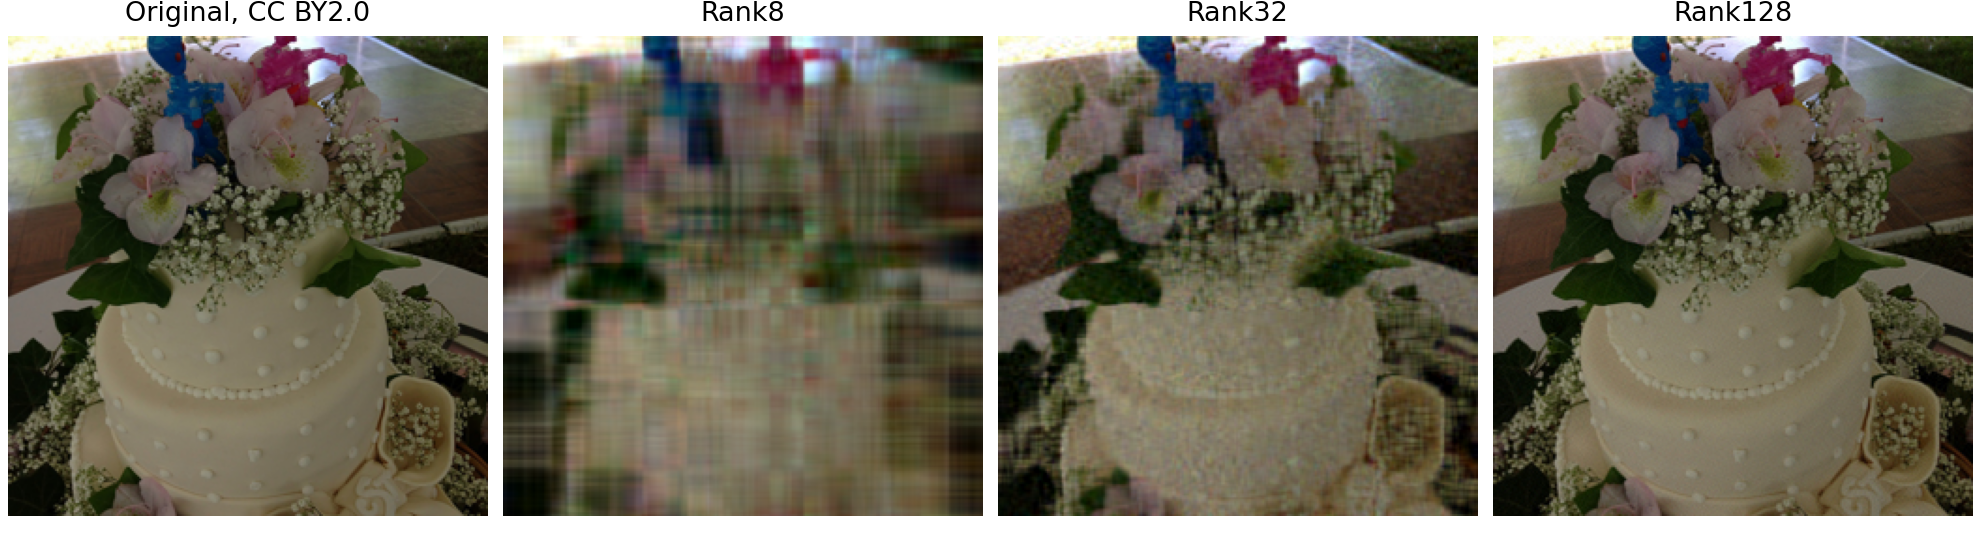

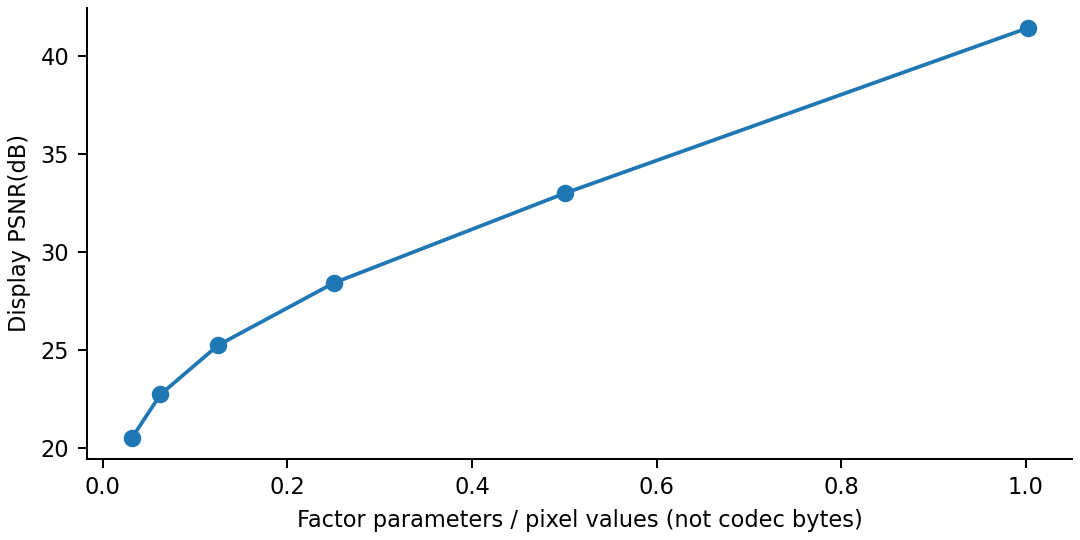

In [4]:
figure("svd_gallery")
figure("svd_frontier")

## Centered PCA subspaces

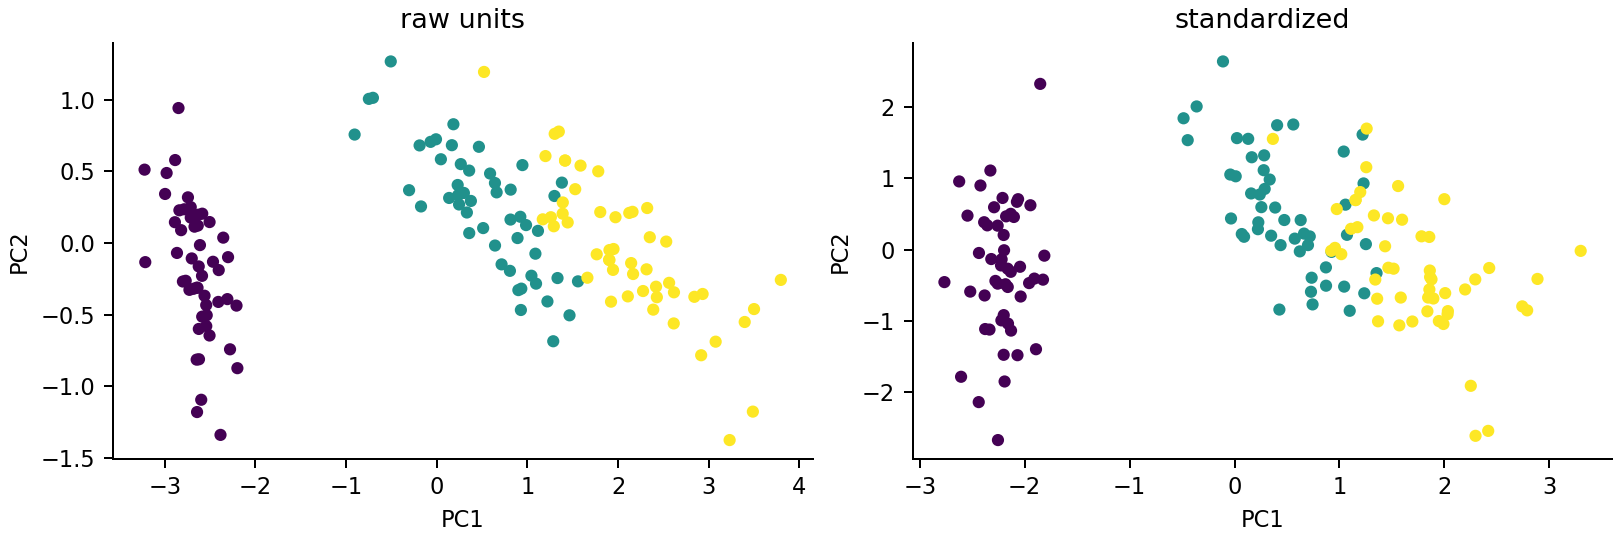

In [5]:
m=read("results/reference/spectral/metrics.json")
assert max(r["sklearn_projector_difference"] for r in m["pca"])<1e-12
figure("pca_units")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.